Upload the grayscale/input image:


Saving pearls.png to pearls.png
Image loaded successfully.


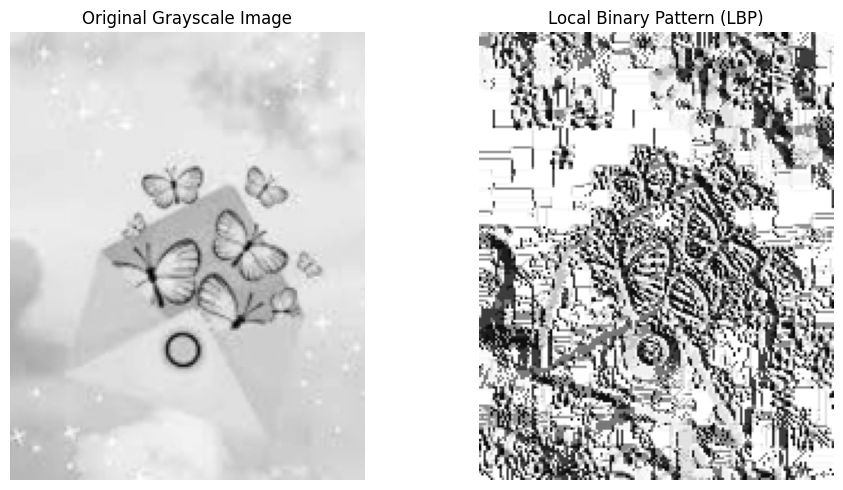

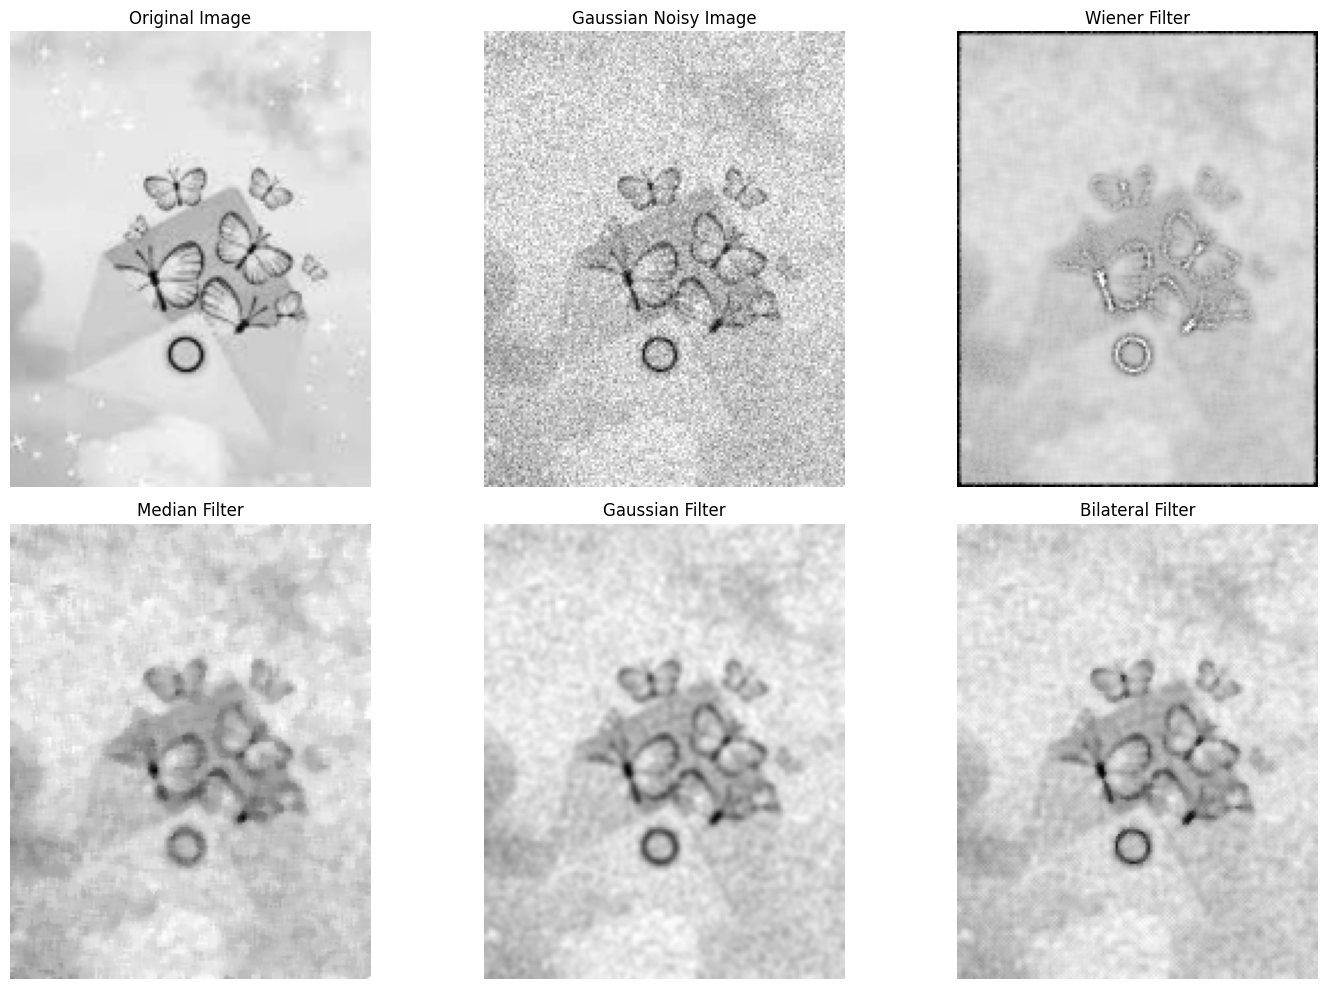

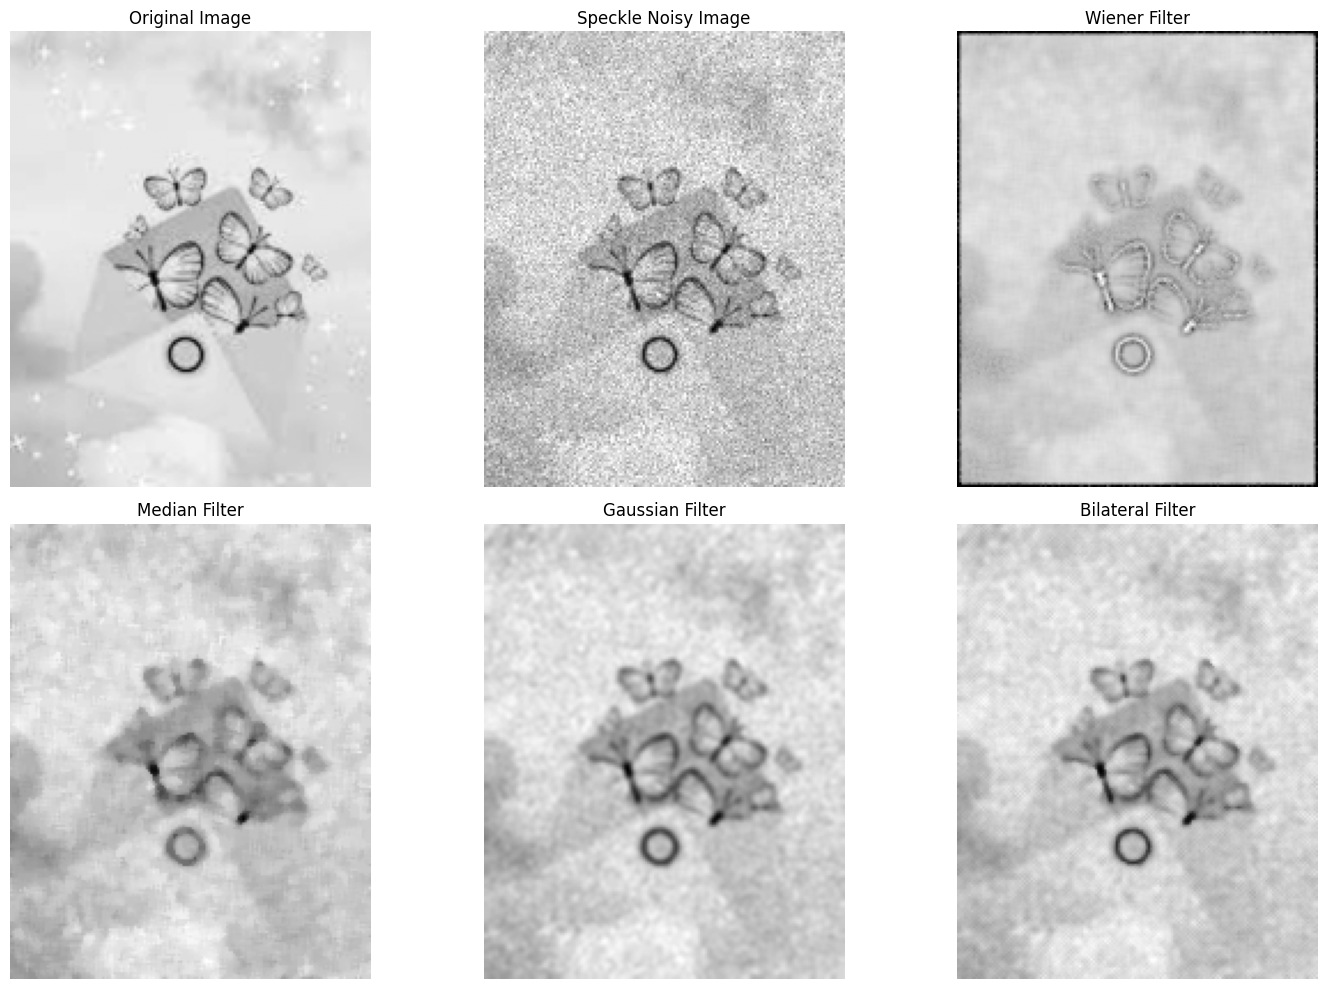

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from scipy.signal import wiener


# ==========================================================
# PART 1: LOCAL BINARY PATTERN (LBP)
# ==========================================================

# Upload image
print("Upload the grayscale/input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read image
image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully.")


# -------- LBP Function --------

def calculate_lbp(image):
    """
    Calculate Local Binary Pattern for a grayscale image.
    Uses 3x3 neighborhood and 8 neighboring pixels.
    """

    rows, cols = image.shape

    # Output image
    lbp = np.zeros((rows - 2, cols - 2), dtype=np.uint8)

    # Center pixel
    center = image[1:-1, 1:-1]

    # 8 neighboring pixels
    neighbors = [
        image[:-2, :-2],       # Top-left
        image[:-2, 1:-1],      # Top
        image[:-2, 2:],        # Top-right
        image[1:-1, 2:],       # Right
        image[2:, 2:],         # Bottom-right
        image[2:, 1:-1],       # Bottom
        image[2:, :-2],        # Bottom-left
        image[1:-1, :-2]       # Left
    ]

    # Calculate binary pattern
    for i, neighbor in enumerate(neighbors):
        lbp |= ((neighbor >= center).astype(np.uint8) << i)

    return lbp


# Calculate LBP
lbp_image = calculate_lbp(image)


# ==========================================================
# PART 2: ADD GAUSSIAN NOISE
# ==========================================================

# Convert image to float
image_float = image.astype(np.float32) / 255.0

# Gaussian noise
mean = 0
sigma = 0.08

gaussian_noise = np.random.normal(
    mean,
    sigma,
    image_float.shape
)

gaussian_noisy = image_float + gaussian_noise

gaussian_noisy = np.clip(
    gaussian_noisy,
    0,
    1
)

gaussian_noisy = (gaussian_noisy * 255).astype(np.uint8)


# ==========================================================
# PART 3: ADD SPECKLE NOISE
# ==========================================================

# Speckle noise is multiplicative noise

speckle_noise = np.random.normal(
    0,
    sigma,
    image_float.shape
)

speckle_noisy = image_float + image_float * speckle_noise

speckle_noisy = np.clip(
    speckle_noisy,
    0,
    1
)

speckle_noisy = (speckle_noisy * 255).astype(np.uint8)


# ==========================================================
# PART 4: DENOISING FUNCTIONS
# ==========================================================

def apply_filters(noisy_image):

    # ------------------------------------------------------
    # (a) Wiener Filter
    # ------------------------------------------------------
    wiener_result = wiener(
        noisy_image,
        (5, 5)
    )

    wiener_result = np.clip(
        wiener_result,
        0,
        255
    ).astype(np.uint8)


    # ------------------------------------------------------
    # (b) Median Filter
    # ------------------------------------------------------
    median_result = cv2.medianBlur(
        noisy_image,
        5
    )


    # ------------------------------------------------------
    # (c) Gaussian Filter
    # ------------------------------------------------------
    gaussian_result = cv2.GaussianBlur(
        noisy_image,
        (5, 5),
        0
    )


    # ------------------------------------------------------
    # (d) Bilateral Filter
    # ------------------------------------------------------
    bilateral_result = cv2.bilateralFilter(
        noisy_image,
        5,
        75,
        75
    )

    return (
        wiener_result,
        median_result,
        gaussian_result,
        bilateral_result
    )


# Apply filters to Gaussian noisy image
(
    gaussian_wiener,
    gaussian_median,
    gaussian_gaussian,
    gaussian_bilateral
) = apply_filters(gaussian_noisy)


# Apply filters to Speckle noisy image
(
    speckle_wiener,
    speckle_median,
    speckle_gaussian,
    speckle_bilateral
) = apply_filters(speckle_noisy)


# ==========================================================
# PART 5: DISPLAY LBP
# ==========================================================

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp_image, cmap='gray')
plt.title("Local Binary Pattern (LBP)")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================================
# PART 6: GAUSSIAN NOISE RESULTS
# ==========================================================

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(gaussian_wiener, cmap='gray')
plt.title("Wiener Filter")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(gaussian_median, cmap='gray')
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(gaussian_gaussian, cmap='gray')
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(gaussian_bilateral, cmap='gray')
plt.title("Bilateral Filter")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================================
# PART 7: SPECKLE NOISE RESULTS
# ==========================================================

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(speckle_wiener, cmap='gray')
plt.title("Wiener Filter")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(speckle_median, cmap='gray')
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(speckle_gaussian, cmap='gray')
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(speckle_bilateral, cmap='gray')
plt.title("Bilateral Filter")
plt.axis("off")

plt.tight_layout()
plt.show()